# CNN-LSTM-CTC — IAM preprocessing parameter validation
Frozen trained epoch 14 checkpoint; same fixed 100 IAM validation lines as checkpoint selection. No training or test access. Reuse all six prespecified validation grids: 5 denoising, 5 deskew, 5 CLAHE, 1 grayscale, 1 intensity and 5 size settings, plus one shared baseline. No combinations. Mandatory checkpoint grayscale/height-64 preparation and greedy CTC decoding always follow optional preprocessing.

Rank active settings by corpus CER then WER; exact ties retain grid order. Also report winners including baseline, which wins equal-score ties. Best means best **among this grid on these 100 validation lines**, not a general optimum or independent performance estimate. Labels remain unchanged; scoring collapses whitespace and retains case/punctuation. Grayscale may duplicate mandatory conversion; size settings add resampling before required resizing.

Results and resumable prediction checkpoints are saved under results/validation/cnn_iam/<UTC run ID>/. Rerun evaluation only to resume. Metadata includes checkpoint hash, dataset revision, exact indices, configurations and software versions.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from datetime import datetime, timezone
from importlib.metadata import version, packages_distributions
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/load_dataset/iam.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import torch
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.models import CNNLSTMCTCRecognizer
from src.preprocessing import PreprocessingPipeline
from src.validation.cnn import configurations, evaluate, select_settings
TRAINING_DIR = ROOT / "results/cnn_lstm_ctc/training/20261114_baseline/iam"
training = json.loads((TRAINING_DIR / "metadata.json").read_text())["identity"]
DATASET_REVISION = training["provenance"]["revision"]
indices = training["validation_indices"]
assert len(indices) == 100 and len(set(indices)) == 100
CHECKPOINT = TRAINING_DIR / "best.pt"
SEED = 5112
torch.set_num_threads(4)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
model = CNNLSTMCTCRecognizer.from_checkpoint(CHECKPOINT, device="cpu")
model.model.eval()
assert model.to_config()["checkpoint_epoch"] == 14
grids = configurations()
full_dataset = load_iam_dataset("validation", revision=DATASET_REVISION)
dataset = full_dataset.select(indices)
samples = [{"id": f"sample_{i}", "image": row["image"], "ground_truth": row["text"]} for i, row in zip(indices, dataset)]
assert all(isinstance(s["ground_truth"], str) and s["ground_truth"].strip() for s in samples)
OUTPUT = ROOT / "results/validation/cnn_iam" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT.mkdir(parents=True, exist_ok=False)
metadata = {"split": "validation", "dataset": "Teklia/IAM-line", "dataset_revision": DATASET_REVISION,
            "sample_indices": indices, "sample_count": len(samples), "full_split_size": len(full_dataset),
            "dataset_fingerprint": dataset._fingerprint, "model": model.to_config(), "seed": SEED,
            "selection": "lowest active corpus CER then WER; stable grid order on ties; also compare baseline",
            "normalization": "collapse whitespace; preserve case/punctuation",
            "configurations": {t: {n: s.to_config() if s else None for n, s in g.items()} for t, g in grids.items()},
            "versions": {p: version(p) for p in ("torch", "datasets", "pillow", "numpy", "pandas", "jiwer")},
            "cv2": cv2.__version__, "python": platform.python_version(), "test_loaded": False}
(OUTPUT / "metadata.json").write_text(json.dumps(metadata, indent=2))
pd.DataFrame([{"sample_id": s["id"], "dataset_index": i, "ground_truth": s["ground_truth"]} for i, s in zip(indices, samples)]).to_csv(OUTPUT / "samples.csv", index=False)
print("Output:", OUTPUT)
print("Validation lines:", len(samples), "| active settings:", sum(len(g)-1 for g in grids.values()))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/cnn_iam/20261116T031934197602Z
Validation lines: 100 | active settings: 22


In [2]:
assert hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest() == metadata["model"]["checkpoint_sha256"]
assert model.to_config() == metadata["model"]
# One baseline is shared across all six studies on identical ordered samples.
baseline = evaluate(samples, model, PreprocessingPipeline(), OUTPUT / "baseline")
records = []
for technique, grid in grids.items():
    records.append({"dataset": "iam", "technique": technique, "configuration": "baseline", **baseline})
    for name, step in grid.items():
        if step is None:
            continue
        score = evaluate(samples, model, PreprocessingPipeline((step,)), OUTPUT / technique / name)
        records.append({"dataset": "iam", "technique": technique, "configuration": name, **score})
        pd.DataFrame(records).to_csv(OUTPUT / "comparison.csv", index=False)
table = pd.DataFrame(records)
for metric in ("cer", "wer"):
    table[metric + "_delta_vs_baseline"] = table[metric] - baseline[metric]
table.to_csv(OUTPUT / "comparison.csv", index=False)
selected = select_settings(table, grids)
selection = {"validation_run": str(OUTPUT.relative_to(ROOT)), "dataset_revision": DATASET_REVISION,
             "model": metadata["model"], "sample_indices": indices, "settings": selected}
(OUTPUT / "selected_settings.json").write_text(json.dumps(selection, indent=2))
selected_table = pd.DataFrame([{"technique": t, **s} for t, s in selected.items()])
selected_table.to_csv(OUTPUT / "selected_settings.csv", index=False)
print("Baseline:", baseline)
display(selected_table.drop(columns="parameters"))

baseline: 10/100
baseline: 20/100
baseline: 30/100
baseline: 40/100
baseline: 50/100
baseline: 60/100
baseline: 70/100
baseline: 80/100
baseline: 90/100
baseline: 100/100
nlm_h1: 10/100
nlm_h1: 20/100
nlm_h1: 30/100
nlm_h1: 40/100
nlm_h1: 50/100
nlm_h1: 60/100
nlm_h1: 70/100
nlm_h1: 80/100
nlm_h1: 90/100
nlm_h1: 100/100
nlm_h3: 10/100
nlm_h3: 20/100
nlm_h3: 30/100
nlm_h3: 40/100
nlm_h3: 50/100
nlm_h3: 60/100
nlm_h3: 70/100
nlm_h3: 80/100
nlm_h3: 90/100
nlm_h3: 100/100
nlm_h7: 10/100
nlm_h7: 20/100
nlm_h7: 30/100
nlm_h7: 40/100
nlm_h7: 50/100
nlm_h7: 60/100
nlm_h7: 70/100
nlm_h7: 80/100
nlm_h7: 90/100
nlm_h7: 100/100
nlm_template3: 10/100
nlm_template3: 20/100
nlm_template3: 30/100
nlm_template3: 40/100
nlm_template3: 50/100
nlm_template3: 60/100
nlm_template3: 70/100
nlm_template3: 80/100
nlm_template3: 90/100
nlm_template3: 100/100
nlm_search11: 10/100
nlm_search11: 20/100
nlm_search11: 30/100
nlm_search11: 40/100
nlm_search11: 50/100
nlm_search11: 60/100
nlm_search11: 70/100
nlm_sear

,technique,configuration,cer,wer,winner_including_baseline,improves_baseline
0,denoising,nlm_h1,0.100702,0.342949,baseline,False
1,deskew,deskew_max5_step0.5,0.101833,0.352564,baseline,False
2,clahe,clahe_clip1_grid8x8,0.104322,0.354701,baseline,False
3,grayscale,grayscale,0.100702,0.342949,baseline,False
4,intensity_normalization,intensity_normalization,0.099796,0.334402,intensity_normalization,True
5,size_normalization,size_height48,0.099570,0.336538,size_height48,True


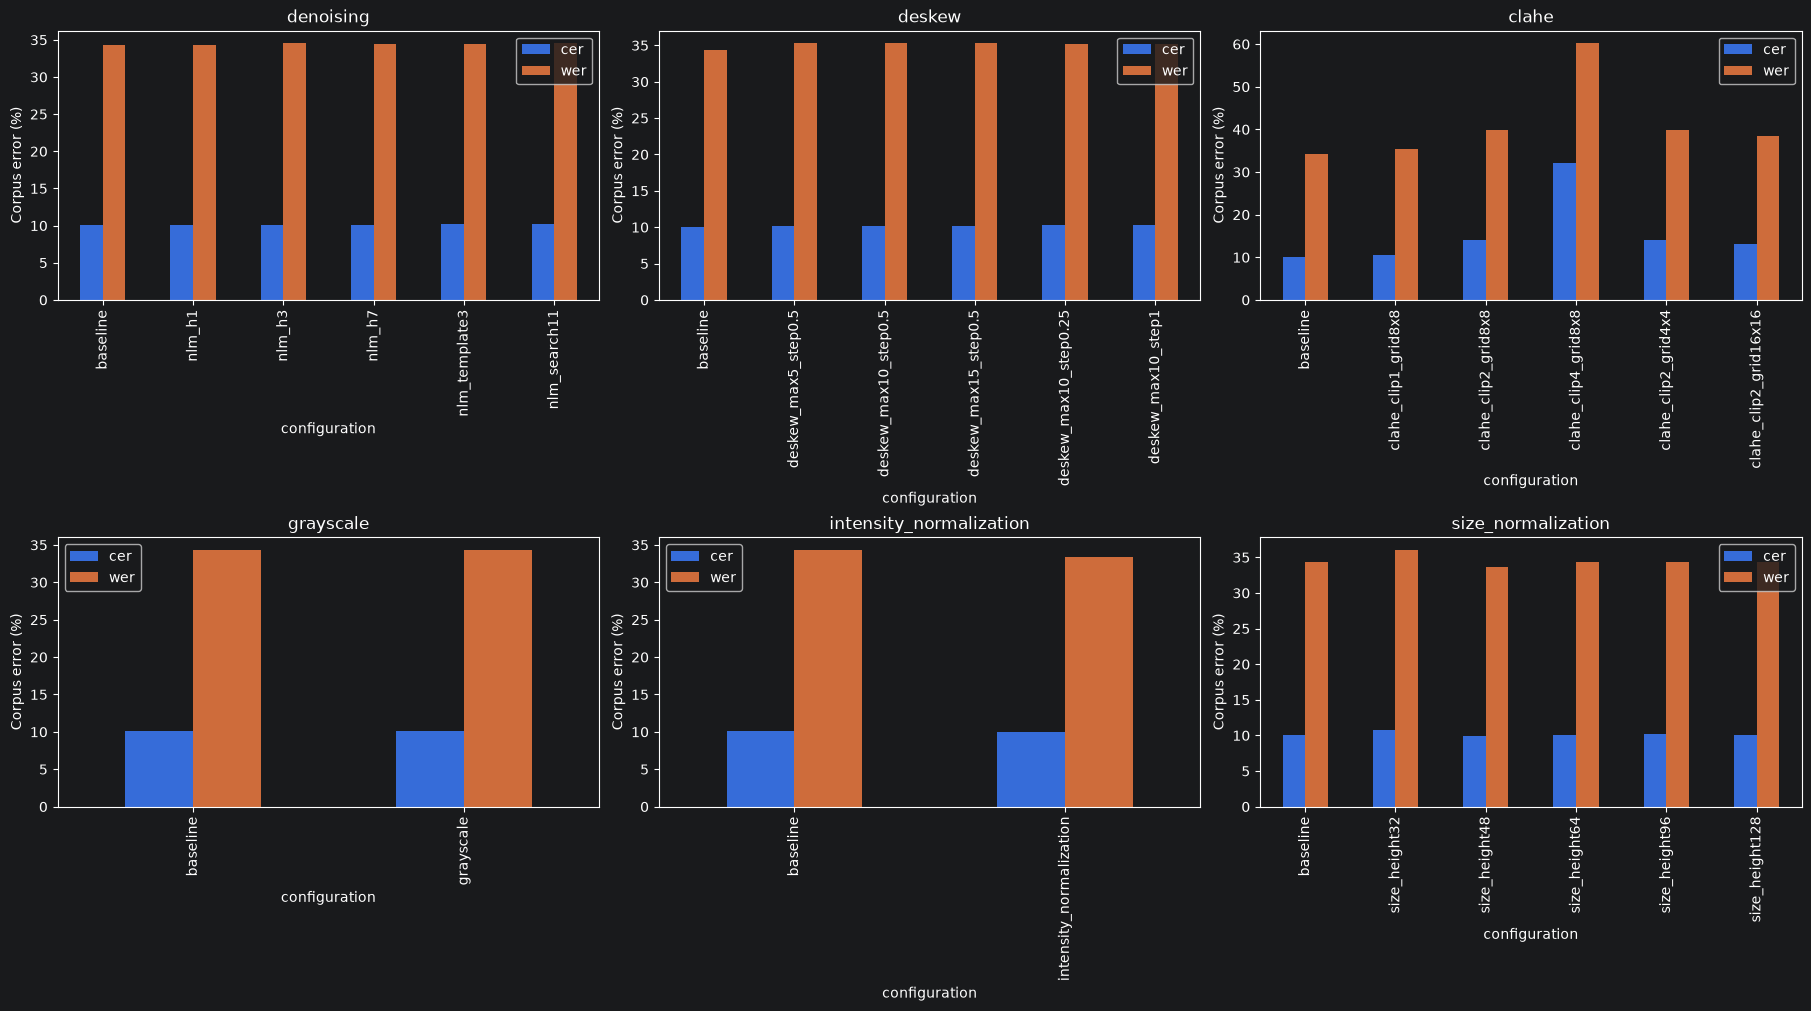

,technique,configuration,sample_count,cer,wer,cer_delta_vs_baseline,wer_delta_vs_baseline
0,denoising,baseline,100,0.100702,0.342949,0.000000,0.000000
1,denoising,nlm_h1,100,0.100702,0.342949,0.000000,0.000000
2,denoising,nlm_h3,100,0.101154,0.345085,0.000453,0.002137
3,denoising,nlm_h7,100,0.101380,0.344017,0.000679,0.001068
4,denoising,nlm_template3,100,0.101607,0.344017,0.000905,0.001068
5,denoising,nlm_search11,100,0.101607,0.345085,0.000905,0.002137
6,deskew,baseline,100,0.100702,0.342949,0.000000,0.000000
7,deskew,deskew_max5_step0.5,100,0.101833,0.352564,0.001131,0.009615
8,deskew,deskew_max10_step0.5,100,0.101833,0.352564,0.001131,0.009615
9,deskew,deskew_max15_step0.5,100,0.101833,0.352564,0.001131,0.009615


Saved selections: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/cnn_iam/20261116T031934197602Z/selected_settings.json


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), layout="constrained")
for ax, (technique, group) in zip(axes.flat, table.groupby("technique", sort=False)):
    group.set_index("configuration")[["cer", "wer"]].mul(100).plot.bar(ax=ax)
    ax.set_title(technique)
    ax.set_ylabel("Corpus error (%)")
fig.savefig(OUTPUT / "validation_grid.png", dpi=160, bbox_inches="tight")
plt.show()
display(table[["technique", "configuration", "sample_count", "cer", "wer", "cer_delta_vs_baseline", "wer_delta_vs_baseline"]])
print("Saved selections:", OUTPUT / "selected_settings.json")